<a href="https://colab.research.google.com/github/yashkumarcs24-bmsce/Bio-Inspired-Systems-Lab/blob/main/Ant_Colony_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== ACO VEHICLE ROUTING RESULT ==========
Number of customers : 8
Number of vehicles  : 3
Vehicle capacity    : 10
Number of ants      : 25
Maximum iterations  : 100

Vehicle 1: Depot -> C6 -> C5 -> C4 -> C3 -> Depot
Load: 10/10

Vehicle 2: Depot -> C2 -> C1 -> C8 -> C7 -> Depot
Load: 10/10

Best total distance : 262.9
Vehicles used       : 2
Total customer demand: 20
Execution time      : 0.4458 seconds


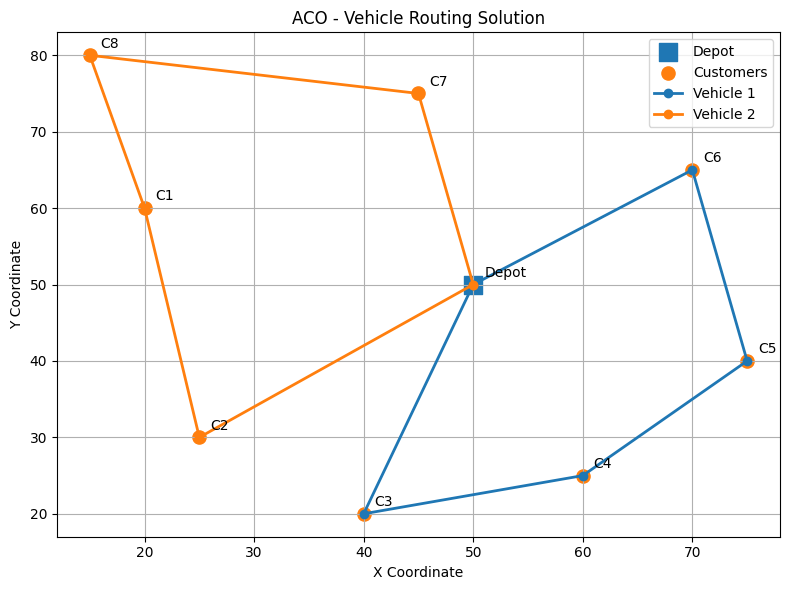

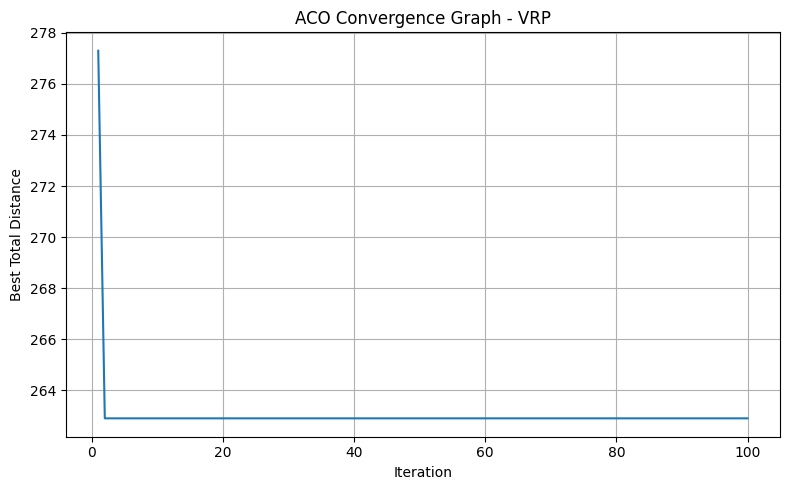


Upload your ACO reference screenshot:


In [ ]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt
from IPython.display import display, Image
from google.colab import files
import io

# ============================================================
# ANT COLONY OPTIMIZATION FOR VEHICLE ROUTING PROBLEM (VRP)
# ============================================================

# -------------------- STEP 1: INPUT DATA --------------------

# Node 0 represents the depot.
# Nodes 1 to 8 represent customers.

coordinates = np.array([
    [50, 50],  # Depot
    [20, 60],  # Customer 1
    [25, 30],  # Customer 2
    [40, 20],  # Customer 3
    [60, 25],  # Customer 4
    [75, 40],  # Customer 5
    [70, 65],  # Customer 6
    [45, 75],  # Customer 7
    [15, 80]   # Customer 8
], dtype=float)

demands = [0, 2, 3, 4, 2, 3, 1, 2, 3]

vehicle_capacity = 10
number_of_vehicles = 3

# ACO Parameters
number_of_ants = 25
max_iterations = 100

alpha = 1.0
beta = 2.0
rho = 0.5
Q = 100.0

initial_pheromone = 1.0

random.seed(42)
np.random.seed(42)

number_of_nodes = len(coordinates)
number_of_customers = number_of_nodes - 1


# -------------------- STEP 2: DISTANCE MATRIX --------------------

distance = np.zeros((number_of_nodes, number_of_nodes))

for i in range(number_of_nodes):
    for j in range(number_of_nodes):
        distance[i][j] = np.linalg.norm(
            coordinates[i] - coordinates[j]
        )

# Heuristic desirability
# eta(i,j) = 1 / distance(i,j)

heuristic = 1 / (distance + 1e-10)
np.fill_diagonal(heuristic, 0)

# Initialize pheromone trails

pheromone = np.full(
    (number_of_nodes, number_of_nodes),
    initial_pheromone
)

np.fill_diagonal(pheromone, 0)


# -------------------- STEP 3: SELECT NEXT CUSTOMER --------------------

def select_next_customer(current, candidates):

    desirability = []

    for customer in candidates:

        value = (
            pheromone[current][customer] ** alpha
        ) * (
            heuristic[current][customer] ** beta
        )

        desirability.append(value)

    probabilities = np.array(desirability, dtype=float)

    probabilities = probabilities / probabilities.sum()

    next_customer = random.choices(
        candidates,
        weights=probabilities,
        k=1
    )[0]

    return next_customer


# -------------------- STEP 4: CONSTRUCT ANT SOLUTION --------------------

def construct_solution():

    unvisited = set(range(1, number_of_nodes))

    routes = []

    total_distance = 0.0

    for vehicle in range(number_of_vehicles):

        if not unvisited:
            break

        route = [0]

        current = 0

        remaining_capacity = vehicle_capacity

        while unvisited:

            feasible = [
                customer
                for customer in unvisited
                if demands[customer] <= remaining_capacity
            ]

            if not feasible:
                break

            next_customer = select_next_customer(
                current,
                feasible
            )

            route.append(next_customer)

            total_distance += distance[current][next_customer]

            remaining_capacity -= demands[next_customer]

            unvisited.remove(next_customer)

            current = next_customer

        # Return vehicle to depot

        if len(route) > 1:

            total_distance += distance[current][0]

            route.append(0)

            routes.append(route)

    # Check whether all customers were visited

    if unvisited:
        return None, float("inf")

    return routes, total_distance


# -------------------- STEP 5: ACO MAIN PROCESS --------------------

best_routes = None

best_distance = float("inf")

convergence = []

start_time = time.time()

for iteration in range(max_iterations):

    iteration_best_routes = None

    iteration_best_distance = float("inf")

    # Each ant constructs a solution

    for ant in range(number_of_ants):

        routes, route_distance = construct_solution()

        if route_distance < iteration_best_distance:

            iteration_best_distance = route_distance

            iteration_best_routes = routes

    # Update global best solution

    if iteration_best_distance < best_distance:

        best_distance = iteration_best_distance

        best_routes = iteration_best_routes

    # Pheromone evaporation

    pheromone *= (1 - rho)

    # Best ant deposits pheromone

    if iteration_best_routes is not None:

        deposit = Q / iteration_best_distance

        for route in iteration_best_routes:

            for i in range(len(route) - 1):

                a = route[i]

                b = route[i + 1]

                pheromone[a][b] += deposit

                pheromone[b][a] += deposit

    convergence.append(best_distance)

elapsed_time = time.time() - start_time


# -------------------- STEP 6: DISPLAY TEXTUAL OUTPUT --------------------

print("\n========== ACO VEHICLE ROUTING RESULT ==========")

print("Number of customers :", number_of_customers)

print("Number of vehicles  :", number_of_vehicles)

print("Vehicle capacity    :", vehicle_capacity)

print("Number of ants      :", number_of_ants)

print("Maximum iterations  :", max_iterations)

if best_routes is None:

    print("\nNo feasible solution found.")

else:

    total_load = 0

    for index, route in enumerate(best_routes, start=1):

        load = sum(
            demands[node]
            for node in route
            if node != 0
        )

        total_load += load

        route_text = " -> ".join(
            "Depot" if node == 0 else f"C{node}"
            for node in route
        )

        print(f"\nVehicle {index}: {route_text}")

        print(f"Load: {load}/{vehicle_capacity}")

    print("\nBest total distance :", round(best_distance, 2))

    print("Vehicles used       :", len(best_routes))

    print("Total customer demand:", total_load)

print("Execution time      :", round(elapsed_time, 4), "seconds")

print("================================================")


# -------------------- STEP 7: VEHICLE ROUTE GRAPH --------------------

if best_routes is not None:

    plt.figure(figsize=(8, 6))

    # Plot depot

    plt.scatter(
        coordinates[0][0],
        coordinates[0][1],
        marker="s",
        s=180,
        label="Depot"
    )

    # Plot customers

    plt.scatter(
        coordinates[1:, 0],
        coordinates[1:, 1],
        marker="o",
        s=90,
        label="Customers"
    )

    # Add node labels

    for node in range(number_of_nodes):

        label = "Depot" if node == 0 else f"C{node}"

        plt.annotate(
            label,
            coordinates[node] + [1, 1]
        )

    # Draw vehicle routes

    for index, route in enumerate(best_routes, start=1):

        x = [coordinates[node][0] for node in route]

        y = [coordinates[node][1] for node in route]

        plt.plot(
            x,
            y,
            marker="o",
            linewidth=2,
            label=f"Vehicle {index}"
        )

    plt.title("ACO - Vehicle Routing Solution")

    plt.xlabel("X Coordinate")

    plt.ylabel("Y Coordinate")

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.show()


# -------------------- STEP 8: CONVERGENCE GRAPH --------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence
)

plt.title("ACO Convergence Graph - VRP")

plt.xlabel("Iteration")

plt.ylabel("Best Total Distance")

plt.grid(True)

plt.tight_layout()

plt.show()


# -------------------- STEP 9: DISPLAY UPLOADED REFERENCE IMAGE --------------------

print("\nUpload your ACO reference screenshot:")

uploaded = files.upload()

for filename in uploaded.keys():

    print("\nDisplaying:", filename)

    display(Image(data=uploaded[filename]))

Number of Customers: 20
Vehicle Capacity: 15
Customer Demands: [4 4 1 2 4 5 3 5 5 2 5 2 2 4 4 1 5 1 5 1]

========== ACO VEHICLE ROUTING RESULT ==========

Vehicle 1:
Route: 0 -> 10 -> 12 -> 16 -> 4 -> 18 -> 14 -> 20 -> 3 -> 0
Total Load: 14/15

Vehicle 2:
Route: 0 -> 11 -> 6 -> 15 -> 0
Total Load: 14/15

Vehicle 3:
Route: 0 -> 7 -> 17 -> 8 -> 13 -> 0
Total Load: 15/15

Vehicle 4:
Route: 0 -> 19 -> 2 -> 5 -> 0
Total Load: 13/15

Vehicle 5:
Route: 0 -> 9 -> 1 -> 0
Total Load: 9/15

Total Distance: 727.63
Vehicles Used: 5

Execution Time: 256.99 ms

========== ACO RUNTIME ANALYSIS ==========

No. of Customers     ACO Runtime (ms)    
----------------------------------------
10                   28.60               
20                   36.16               
30                   58.58               
40                   93.33               
50                   121.87              
60                   204.24              
70                   439.25              
80                   276.

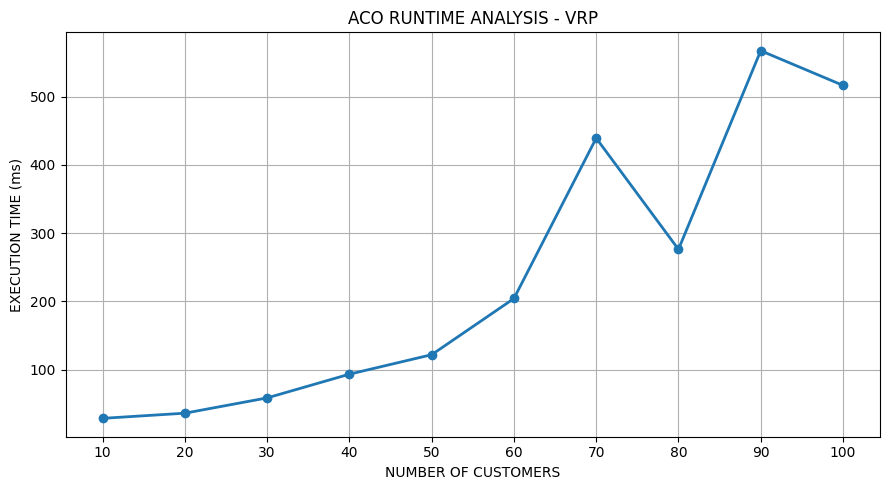

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import time

# ---------------------------------------------------------
# STEP 1: GENERATE VRP DATA
# ---------------------------------------------------------

def generate_vrp_data(n, seed=42):
    rng = np.random.default_rng(seed)

    # Node 0 is the depot; remaining nodes are customers
    coordinates = rng.uniform(0, 100, (n + 1, 2))

    # Customer demands (depot demand is zero)
    demands = np.zeros(n + 1, dtype=int)
    demands[1:] = rng.integers(1, 6, n)

    return coordinates, demands


# ---------------------------------------------------------
# STEP 2: CALCULATE DISTANCE MATRIX
# ---------------------------------------------------------

def calculate_distance_matrix(coordinates):
    n = len(coordinates)
    distance = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            distance[i][j] = np.linalg.norm(
                coordinates[i] - coordinates[j]
            )

    return distance


# ---------------------------------------------------------
# STEP 3: CALCULATE ROUTE DISTANCE
# ---------------------------------------------------------

def calculate_route_distance(routes, distance):
    total_distance = 0

    for route in routes:
        for i in range(len(route) - 1):
            total_distance += distance[route[i]][route[i + 1]]

    return total_distance


# ---------------------------------------------------------
# STEP 4: CONSTRUCT A SOLUTION USING AN ANT
# ---------------------------------------------------------

def construct_solution(distance, demands, capacity,
                       pheromone, alpha, beta, rng):

    n = len(demands) - 1
    unvisited = set(range(1, n + 1))
    routes = []

    while unvisited:
        current = 0
        remaining_capacity = capacity
        route = [0]

        while True:

            # Find customers that can be visited
            allowed = [
                customer for customer in unvisited
                if demands[customer] <= remaining_capacity
            ]

            if not allowed:
                break

            # Calculate transition probabilities
            probabilities = []

            for customer in allowed:
                tau = pheromone[current][customer]
                eta = 1 / (distance[current][customer] + 1e-10)

                probability = (tau ** alpha) * (eta ** beta)
                probabilities.append(probability)

            probabilities = np.array(probabilities)
            probabilities = probabilities / probabilities.sum()

            # Select the next customer probabilistically
            next_customer = rng.choice(
                allowed, p=probabilities
            )

            route.append(next_customer)
            unvisited.remove(next_customer)

            remaining_capacity -= demands[next_customer]
            current = next_customer

        # Return to depot
        route.append(0)
        routes.append(route)

    return routes


# ---------------------------------------------------------
# STEP 5: ANT COLONY OPTIMIZATION
# ---------------------------------------------------------

def run_aco(coordinates, demands, capacity,
            n_ants=10, iterations=30,
            alpha=1, beta=2, rho=0.5, Q=100,
            vehicle_penalty=20, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    distance = calculate_distance_matrix(coordinates)
    n = len(demands)

    # Initialize pheromone levels
    pheromone = np.ones((n, n))

    best_routes = None
    best_distance = float('inf')
    best_objective = float('inf')

    for iteration in range(iterations):

        ant_solutions = []

        # Each ant constructs a solution
        for ant in range(n_ants):

            routes = construct_solution(
                distance, demands, capacity,
                pheromone, alpha, beta, rng
            )

            total_distance = calculate_route_distance(
                routes, distance
            )

            # Objective considers distance and vehicles used
            objective = (
                total_distance + vehicle_penalty * len(routes)
            )

            ant_solutions.append(
                (routes, total_distance, objective)
            )

            if objective < best_objective:
                best_objective = objective
                best_routes = routes
                best_distance = total_distance

        # Select the best ant of this iteration
        iteration_best = min(
            ant_solutions, key=lambda x: x[2]
        )

        # Evaporate pheromone
        pheromone *= (1 - rho)

        # Only the best ant deposits pheromone
        routes, total_distance, objective = iteration_best

        deposit = Q / (objective + 1e-10)

        for route in routes:
            for i in range(len(route) - 1):
                a = route[i]
                b = route[i + 1]

                pheromone[a][b] += deposit
                pheromone[b][a] += deposit

    return best_routes, best_distance


# ---------------------------------------------------------
# STEP 6: DISPLAY TEXTUAL RESULTS
# ---------------------------------------------------------

def display_results(routes, distance, demands, capacity):

    print("\n========== ACO VEHICLE ROUTING RESULT ==========")

    for i, route in enumerate(routes):
        customers = route[1:-1]
        load = sum(demands[c] for c in customers)

        print(f"\nVehicle {i + 1}:")
        print("Route:", " -> ".join(map(str, route)))
        print(f"Total Load: {load}/{capacity}")

    print("\nTotal Distance:", round(distance, 2))
    print("Vehicles Used:", len(routes))
    print("================================================")


# ---------------------------------------------------------
# STEP 7: PERFORMANCE ANALYSIS
# ---------------------------------------------------------

def benchmark_aco():

    customer_counts = list(range(10, 101, 10))
    execution_times = []

    print("\n========== ACO RUNTIME ANALYSIS ==========")

    for n in customer_counts:

        coordinates, demands = generate_vrp_data(
            n, seed=100 + n
        )

        rng = np.random.default_rng(200 + n)

        start_time = time.perf_counter()

        run_aco(
            coordinates,
            demands,
            capacity=15,
            n_ants=5,
            iterations=8,
            alpha=1,
            beta=2,
            rho=0.5,
            Q=100,
            rng=rng
        )

        end_time = time.perf_counter()

        runtime = (end_time - start_time) * 1000
        execution_times.append(runtime)

    # Display performance table
    print("\n{:<20} {:<20}".format(
        "No. of Customers", "ACO Runtime (ms)"
    ))

    print("-" * 40)

    for n, runtime in zip(customer_counts, execution_times):
        print("{:<20} {:<20.2f}".format(n, runtime))

    # Plot runtime graph
    plt.figure(figsize=(9, 5))

    plt.plot(
        customer_counts,
        execution_times,
        marker='o',
        linewidth=2
    )

    plt.title("ACO RUNTIME ANALYSIS - VRP")
    plt.xlabel("NUMBER OF CUSTOMERS")
    plt.ylabel("EXECUTION TIME (ms)")

    plt.xticks(customer_counts)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 8: MAIN FUNCTION
# ---------------------------------------------------------

def main():

    # Problem parameters
    n_customers = 20
    vehicle_capacity = 15

    n_ants = 10
    iterations = 30

    alpha = 1
    beta = 2
    rho = 0.5
    Q = 100

    rng = np.random.default_rng(42)

    # Generate problem data
    coordinates, demands = generate_vrp_data(
        n_customers, seed=42
    )

    print("Number of Customers:", n_customers)
    print("Vehicle Capacity:", vehicle_capacity)
    print("Customer Demands:", demands[1:])

    # Execute ACO
    start_time = time.perf_counter()

    best_routes, best_distance = run_aco(
        coordinates,
        demands,
        vehicle_capacity,
        n_ants,
        iterations,
        alpha,
        beta,
        rho,
        Q,
        rng=rng
    )

    end_time = time.perf_counter()

    # Display final solution
    display_results(
        best_routes,
        best_distance,
        demands,
        vehicle_capacity
    )

    print(
        "\nExecution Time:",
        round((end_time - start_time) * 1000, 2),
        "ms"
    )

    # Generate performance table and graph
    benchmark_aco()


if __name__ == "__main__":
    main()


Number of Customers: 20
Vehicle Capacity: 15
Customer Demands: [4 4 1 2 4 5 3 5 5 2 5 2 2 4 4 1 5 1 5 1]
Run 1: Distance = 682.81, Vehicles = 5
Run 2: Distance = 700.07, Vehicles = 5
Run 3: Distance = 711.59, Vehicles = 5
Run 4: Distance = 694.09, Vehicles = 5
Run 5: Distance = 715.32, Vehicles = 5

========== BEST ACO VRP SOLUTION ==========

Vehicle 1
Route: 0 -> 10 -> 16 -> 4 -> 18 -> 14 -> 19 -> 0
Vehicle Load: 15/15

Vehicle 2
Route: 0 -> 3 -> 6 -> 20 -> 5 -> 2 -> 0
Vehicle Load: 15/15

Vehicle 3
Route: 0 -> 15 -> 11 -> 1 -> 12 -> 0
Vehicle Load: 15/15

Vehicle 4
Route: 0 -> 7 -> 17 -> 13 -> 8 -> 0
Vehicle Load: 15/15

Vehicle 5
Route: 0 -> 9 -> 0
Vehicle Load: 5/15

========== VALIDATION ==========
Every customer visited once: True
Capacity constraints satisfied: True

========== FINAL RESULT ==========
Best Total Distance: 682.81
Vehicles Used: 5

Total Multiple-Run Execution Time: 5738.03 ms

========== ACO RUNTIME ANALYSIS ==========

No. of Customers     ACO Runtime (ms)    


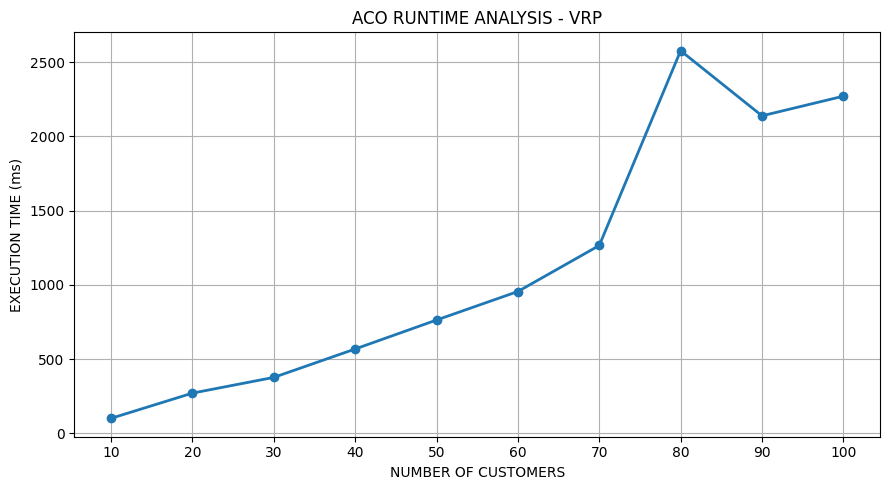

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import time

# =========================================================
# STEP 1: GENERATE VRP DATA
# =========================================================

def generate_vrp_data(n, seed=42):
    rng = np.random.default_rng(seed)

    coordinates = rng.uniform(0, 100, (n + 1, 2))

    demands = np.zeros(n + 1, dtype=int)
    demands[1:] = rng.integers(1, 6, n)

    return coordinates, demands


# =========================================================
# STEP 2: DISTANCE MATRIX
# =========================================================

def calculate_distance_matrix(coordinates):
    n = len(coordinates)
    distance = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            distance[i][j] = np.linalg.norm(
                coordinates[i] - coordinates[j]
            )

    return distance


# =========================================================
# STEP 3: CALCULATE TOTAL DISTANCE
# =========================================================

def calculate_total_distance(routes, distance):
    total = 0

    for route in routes:
        for i in range(len(route) - 1):
            total += distance[route[i]][route[i + 1]]

    return total


# =========================================================
# STEP 4: 2-OPT LOCAL SEARCH
# =========================================================

def two_opt(route, distance):
    best_route = route[:]
    improved = True

    while improved:
        improved = False
        best_distance = calculate_total_distance(
            [best_route], distance
        )

        for i in range(1, len(best_route) - 2):
            for j in range(i + 1, len(best_route) - 1):

                new_route = (
                    best_route[:i]
                    + best_route[i:j + 1][::-1]
                    + best_route[j + 1:]
                )

                new_distance = calculate_total_distance(
                    [new_route], distance
                )

                if new_distance < best_distance - 1e-9:
                    best_route = new_route
                    best_distance = new_distance
                    improved = True
                    break

            if improved:
                break

    return best_route


def improve_solution(routes, distance):
    return [
        two_opt(route, distance)
        for route in routes
    ]


# =========================================================
# STEP 5: CONSTRUCT SOLUTION USING AN ANT
# =========================================================

def construct_solution(distance, demands, capacity,
                       pheromone, alpha, beta, rng):

    n = len(demands) - 1
    unvisited = set(range(1, n + 1))
    routes = []

    while unvisited:

        current = 0
        remaining_capacity = capacity
        route = [0]

        while True:

            allowed = [
                c for c in unvisited
                if demands[c] <= remaining_capacity
            ]

            if not allowed:
                break

            probabilities = []

            for customer in allowed:

                tau = pheromone[current][customer]
                eta = 1 / (distance[current][customer] + 1e-10)

                probabilities.append(
                    (tau ** alpha) * (eta ** beta)
                )

            probabilities = np.array(probabilities)
            probabilities /= probabilities.sum()

            next_customer = rng.choice(
                allowed, p=probabilities
            )

            route.append(next_customer)
            unvisited.remove(next_customer)

            remaining_capacity -= demands[next_customer]
            current = next_customer

        route.append(0)
        routes.append(route)

    return routes


# =========================================================
# STEP 6: ACO ALGORITHM
# =========================================================

def run_aco(coordinates, demands, capacity,
            n_ants=20, iterations=50,
            alpha=1, beta=2, rho=0.5, Q=100,
            vehicle_penalty=20, seed=42):

    rng = np.random.default_rng(seed)

    distance = calculate_distance_matrix(coordinates)
    n = len(demands)

    pheromone = np.ones((n, n))

    best_routes = None
    best_distance = float('inf')
    best_objective = float('inf')

    for iteration in range(iterations):

        iteration_best_routes = None
        iteration_best_objective = float('inf')

        # Each ant constructs a solution
        for ant in range(n_ants):

            routes = construct_solution(
                distance, demands, capacity,
                pheromone, alpha, beta, rng
            )

            # Improve every vehicle route using 2-opt
            routes = improve_solution(routes, distance)

            total_distance = calculate_total_distance(
                routes, distance
            )

            # Objective considers distance and vehicle count
            objective = (
                total_distance
                + vehicle_penalty * len(routes)
            )

            if objective < iteration_best_objective:
                iteration_best_objective = objective
                iteration_best_routes = routes

            if objective < best_objective:
                best_objective = objective
                best_routes = [r[:] for r in routes]
                best_distance = total_distance

        # Pheromone evaporation
        pheromone *= (1 - rho)

        # Best ant deposits pheromone
        deposit = Q / (iteration_best_objective + 1e-10)

        for route in iteration_best_routes:
            for i in range(len(route) - 1):
                a = route[i]
                b = route[i + 1]

                pheromone[a][b] += deposit
                pheromone[b][a] += deposit

    return best_routes, best_distance


# =========================================================
# STEP 7: MULTIPLE RUNS
# =========================================================

def multiple_runs(coordinates, demands, capacity,
                  runs=5):

    overall_best_routes = None
    overall_best_distance = float('inf')
    overall_best_objective = float('inf')

    start_time = time.perf_counter()

    for run in range(runs):

        routes, distance = run_aco(
            coordinates,
            demands,
            capacity,
            n_ants=20,
            iterations=50,
            alpha=1,
            beta=2,
            rho=0.5,
            Q=100,
            seed=100 + run
        )

        objective = distance + 20 * len(routes)

        print(
            f"Run {run + 1}: Distance = {distance:.2f}, "
            f"Vehicles = {len(routes)}"
        )

        if objective < overall_best_objective:
            overall_best_objective = objective
            overall_best_distance = distance
            overall_best_routes = [r[:] for r in routes]

    end_time = time.perf_counter()

    runtime = (end_time - start_time) * 1000

    return overall_best_routes, overall_best_distance, runtime


# =========================================================
# STEP 8: DISPLAY FINAL RESULT
# =========================================================

def display_results(routes, distance, demands, capacity):

    print("\n========== BEST ACO VRP SOLUTION ==========")

    visited = []

    for i, route in enumerate(routes):

        customers = route[1:-1]
        load = sum(demands[c] for c in customers)

        visited.extend(customers)

        print(f"\nVehicle {i + 1}")
        print("Route:", " -> ".join(map(str, route)))
        print(f"Vehicle Load: {load}/{capacity}")

    # Verify solution
    expected = set(range(1, len(demands)))

    print("\n========== VALIDATION ==========")
    print("Every customer visited once:",
          len(visited) == len(set(visited))
          and set(visited) == expected)

    print("Capacity constraints satisfied:",
          all(
              sum(demands[c] for c in route[1:-1]) <= capacity
              for route in routes
          ))

    print("\n========== FINAL RESULT ==========")
    print("Best Total Distance:", round(distance, 2))
    print("Vehicles Used:", len(routes))
    print("=================================")


# =========================================================
# STEP 9: PERFORMANCE ANALYSIS
# =========================================================

def benchmark_aco():

    customer_counts = list(range(10, 101, 10))
    execution_times = []

    print("\n========== ACO RUNTIME ANALYSIS ==========")

    for n in customer_counts:

        coordinates, demands = generate_vrp_data(
            n, seed=100 + n
        )

        start = time.perf_counter()

        run_aco(
            coordinates,
            demands,
            capacity=15,
            n_ants=10,
            iterations=20,
            seed=200 + n
        )

        end = time.perf_counter()

        runtime = (end - start) * 1000
        execution_times.append(runtime)

    # Performance table
    print("\n{:<20} {:<20}".format(
        "No. of Customers", "ACO Runtime (ms)"
    ))

    print("-" * 40)

    for n, runtime in zip(customer_counts, execution_times):
        print("{:<20} {:<20.2f}".format(n, runtime))

    # Runtime graph
    plt.figure(figsize=(9, 5))

    plt.plot(
        customer_counts,
        execution_times,
        marker='o',
        linewidth=2
    )

    plt.title("ACO RUNTIME ANALYSIS - VRP")
    plt.xlabel("NUMBER OF CUSTOMERS")
    plt.ylabel("EXECUTION TIME (ms)")

    plt.xticks(customer_counts)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =========================================================
# STEP 10: MAIN FUNCTION
# =========================================================

def main():

    n_customers = 20
    vehicle_capacity = 15

    coordinates, demands = generate_vrp_data(
        n_customers, seed=42
    )

    print("Number of Customers:", n_customers)
    print("Vehicle Capacity:", vehicle_capacity)
    print("Customer Demands:", demands[1:])

    # Run ACO multiple times
    best_routes, best_distance, runtime = multiple_runs(
        coordinates,
        demands,
        vehicle_capacity,
        runs=5
    )

    # Display best solution
    display_results(
        best_routes,
        best_distance,
        demands,
        vehicle_capacity
    )

    print("\nTotal Multiple-Run Execution Time:",
          round(runtime, 2), "ms")

    # Performance table and graph
    benchmark_aco()


if __name__ == "__main__":
    main()


Distance Matrix:
 [[ 0  8 13 12 12 13]
 [ 8  0  9  5 12 12]
 [13  9  0 12  9  2]
 [12  5 12  0 10 14]
 [12 12  9 10  0 13]
 [13 12  2 14 13  0]]

Flow Matrix:
 [[ 0 11  7  8  7 12]
 [11  0  6  7  8  9]
 [ 7  6  0  5  5  4]
 [ 8  7  5  0 12  8]
 [ 7  8  5 12  0  7]
 [12  9  4  8  7  0]]

========== ACO QAP RESULT ==========
Facility 3 -> Location 1
Facility 4 -> Location 2
Facility 1 -> Location 3
Facility 5 -> Location 4
Facility 2 -> Location 5
Facility 6 -> Location 6

Minimum Assignment Cost: 2258
Every facility assigned once: True
Execution Time: 1595.14 ms


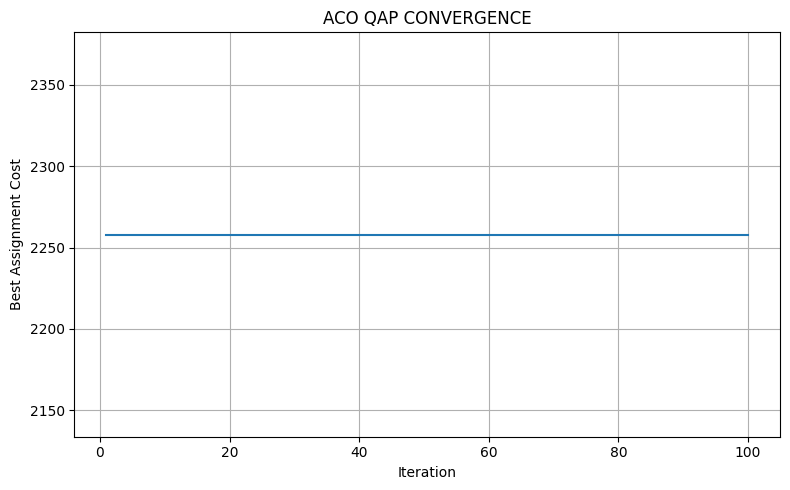


========== QAP RUNTIME ANALYSIS ==========

No. of Facilities    Runtime (ms)        
4                    86.74               
5                    167.58              
6                    283.63              
7                    503.65              
8                    1741.30             
9                    1258.80             
10                   1411.46             


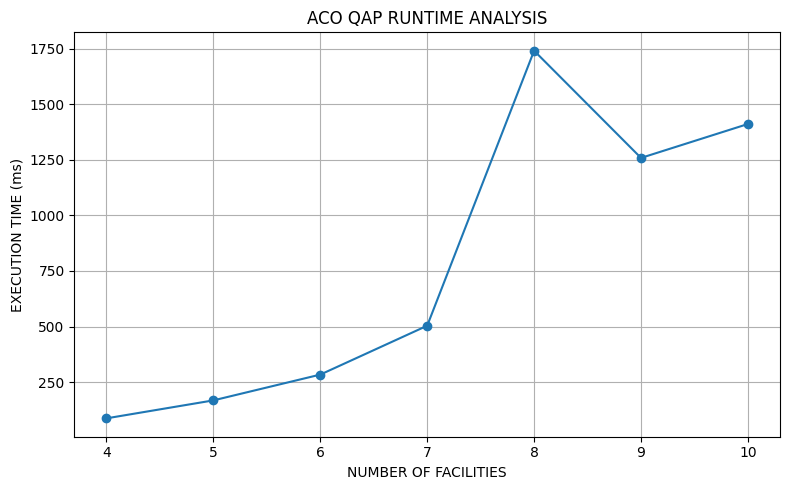

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import time

# ---------------------------------------------------------
# STEP 1: GENERATE QAP DATA
# ---------------------------------------------------------

def generate_qap_data(n, seed=42):

    rng = np.random.default_rng(seed)

    distance = rng.integers(1, 20, (n, n))
    flow = rng.integers(0, 15, (n, n))

    np.fill_diagonal(distance, 0)
    np.fill_diagonal(flow, 0)

    # Make matrices symmetric
    distance = (distance + distance.T) // 2
    flow = (flow + flow.T) // 2

    return distance, flow


# ---------------------------------------------------------
# STEP 2: CALCULATE ASSIGNMENT COST
# ---------------------------------------------------------

def calculate_cost(assignment, distance, flow):

    n = len(assignment)
    cost = 0

    for i in range(n):
        for j in range(n):

            cost += (
                distance[i][j]
                * flow[assignment[i]][assignment[j]]
            )

    return cost


# ---------------------------------------------------------
# STEP 3: CONSTRUCT ASSIGNMENT USING AN ANT
# ---------------------------------------------------------

def construct_assignment(distance, flow,
                         pheromone, alpha, beta, rng):

    n = len(distance)

    assignment = [-1] * n
    available_facilities = set(range(n))

    # Assign facilities one location at a time
    for location in range(n):

        allowed = list(available_facilities)
        probabilities = []

        for facility in allowed:

            tau = pheromone[location][facility]

            # Incremental assignment cost
            incremental_cost = 0

            for previous_location in range(location):

                previous_facility = assignment[previous_location]

                incremental_cost += (
                    distance[location][previous_location]
                    * (
                        flow[facility][previous_facility]
                        + flow[previous_facility][facility]
                    )
                )

            eta = 1 / (incremental_cost + 1)

            probabilities.append(
                (tau ** alpha) * (eta ** beta)
            )

        probabilities = np.array(probabilities)
        probabilities /= probabilities.sum()

        selected = rng.choice(allowed, p=probabilities)

        assignment[location] = selected
        available_facilities.remove(selected)

    return assignment


# ---------------------------------------------------------
# STEP 4: LOCAL SEARCH
# ---------------------------------------------------------

def improve_assignment(assignment, distance, flow):

    best = assignment[:]
    best_cost = calculate_cost(best, distance, flow)

    improved = True

    while improved:

        improved = False

        for i in range(len(best)):
            for j in range(i + 1, len(best)):

                new_assignment = best[:]

                new_assignment[i], new_assignment[j] = (
                    new_assignment[j], new_assignment[i]
                )

                new_cost = calculate_cost(
                    new_assignment, distance, flow
                )

                if new_cost < best_cost:
                    best = new_assignment
                    best_cost = new_cost
                    improved = True
                    break

            if improved:
                break

    return best, best_cost


# ---------------------------------------------------------
# STEP 5: ACO FOR QAP
# ---------------------------------------------------------

def aco_qap(distance, flow, ants=20,
            iterations=100, alpha=1,
            beta=2, rho=0.5, Q=100, seed=42):

    rng = np.random.default_rng(seed)

    n = len(distance)

    pheromone = np.ones((n, n))

    best_assignment = None
    best_cost = float('inf')

    convergence = []

    for iteration in range(iterations):

        iteration_best = None
        iteration_cost = float('inf')

        for ant in range(ants):

            assignment = construct_assignment(
                distance, flow,
                pheromone, alpha, beta, rng
            )

            assignment, cost = improve_assignment(
                assignment, distance, flow
            )

            if cost < iteration_cost:
                iteration_cost = cost
                iteration_best = assignment[:]

            if cost < best_cost:
                best_cost = cost
                best_assignment = assignment[:]

        # Evaporate pheromone
        pheromone *= (1 - rho)

        # Deposit pheromone for best assignment
        deposit = Q / (iteration_cost + 1e-10)

        for location, facility in enumerate(iteration_best):
            pheromone[location][facility] += deposit

        convergence.append(best_cost)

    return best_assignment, best_cost, convergence


# ---------------------------------------------------------
# STEP 6: DISPLAY ASSIGNMENT
# ---------------------------------------------------------

def display_assignment(assignment, cost):

    print("\n========== ACO QAP RESULT ==========")

    for location, facility in enumerate(assignment):

        print(
            f"Facility {facility + 1} -> Location {location + 1}"
        )

    print("\nMinimum Assignment Cost:", cost)

    print("Every facility assigned once:",
          len(set(assignment)) == len(assignment))

    print("====================================")


# ---------------------------------------------------------
# STEP 7: PERFORMANCE ANALYSIS
# ---------------------------------------------------------

def benchmark():

    sizes = [4, 5, 6, 7, 8, 9, 10]
    times = []

    print("\n========== QAP RUNTIME ANALYSIS ==========")

    for n in sizes:

        distance, flow = generate_qap_data(
            n, seed=100 + n
        )

        start = time.perf_counter()

        aco_qap(
            distance, flow,
            ants=10,
            iterations=20,
            seed=200 + n
        )

        end = time.perf_counter()

        times.append((end - start) * 1000)

    print("\n{:<20} {:<20}".format(
        "No. of Facilities", "Runtime (ms)"
    ))

    for n, t in zip(sizes, times):
        print("{:<20} {:<20.2f}".format(n, t))

    plt.figure(figsize=(8, 5))
    plt.plot(sizes, times, marker='o')

    plt.title("ACO QAP RUNTIME ANALYSIS")
    plt.xlabel("NUMBER OF FACILITIES")
    plt.ylabel("EXECUTION TIME (ms)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 8: MAIN FUNCTION
# ---------------------------------------------------------

def main():

    n = 6

    distance, flow = generate_qap_data(n)

    start = time.perf_counter()

    assignment, cost, convergence = aco_qap(
        distance, flow,
        ants=20,
        iterations=100,
        alpha=1,
        beta=2,
        rho=0.5,
        Q=100
    )

    end = time.perf_counter()

    print("Distance Matrix:\n", distance)
    print("\nFlow Matrix:\n", flow)

    display_assignment(assignment, round(cost, 2))

    print("Execution Time:",
          round((end - start) * 1000, 2), "ms")

    # Convergence graph
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(convergence) + 1), convergence)

    plt.title("ACO QAP CONVERGENCE")
    plt.xlabel("Iteration")
    plt.ylabel("Best Assignment Cost")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    benchmark()


if __name__ == "__main__":
    main()



========== ACO NETWORK ROUTING RESULT ==========
Source Node: 0
Destination Node: 5
Best Path: 0 -> 2 -> 3 -> 4 -> 5
Minimum Path Cost: 11
Execution Time: 275.9 ms


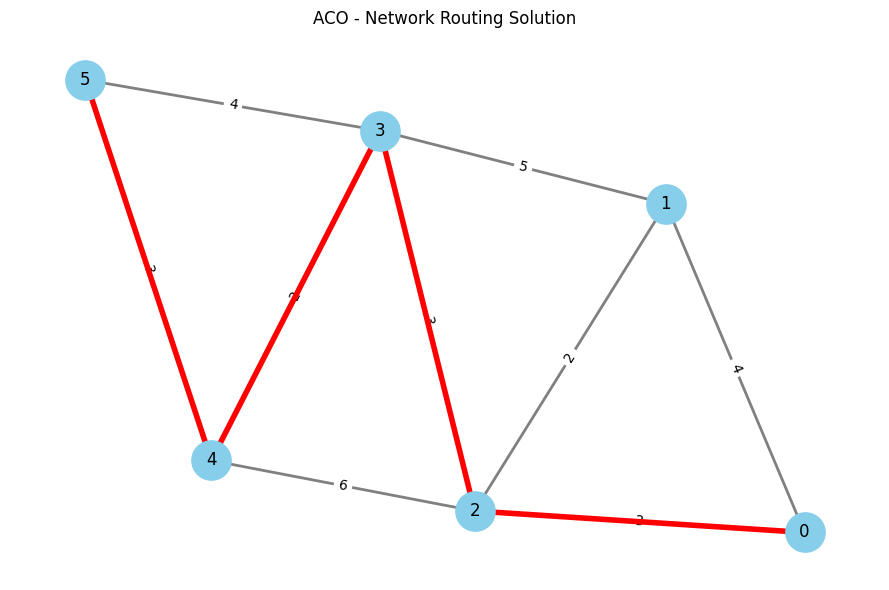

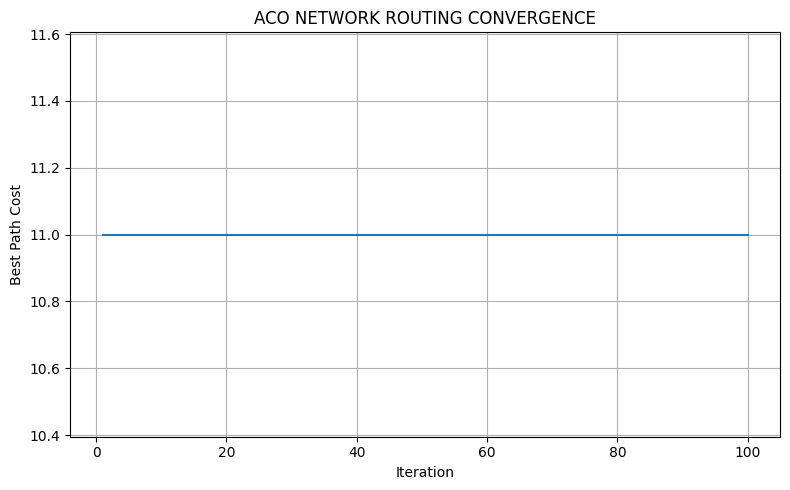


========== NETWORK ROUTING RUNTIME ==========

No. of Nodes         Runtime (ms)        
6                    27.00               
10                   22.09               
15                   59.97               
20                   33.35               
25                   63.19               
30                   84.43               


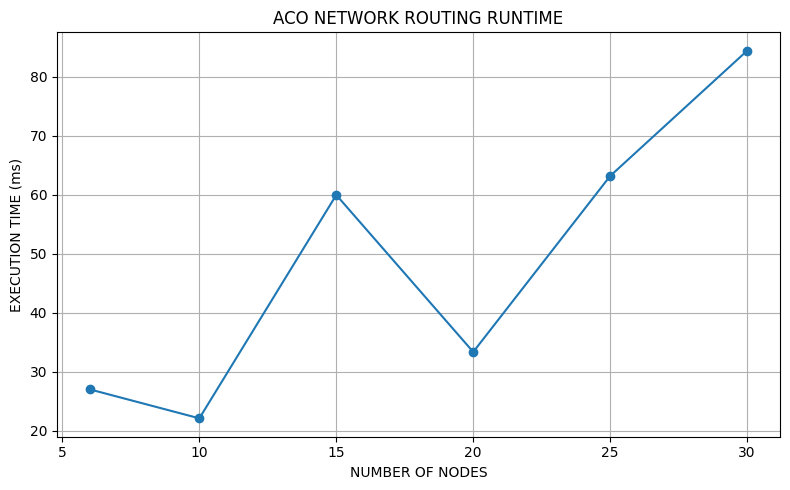

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time

# ---------------------------------------------------------
# STEP 1: CREATE NETWORK
# ---------------------------------------------------------

def create_network():

    graph = {
        0: {1: 4, 2: 3},
        1: {0: 4, 2: 2, 3: 5},
        2: {0: 3, 1: 2, 3: 3, 4: 6},
        3: {1: 5, 2: 3, 4: 2, 5: 4},
        4: {2: 6, 3: 2, 5: 3},
        5: {3: 4, 4: 3}
    }

    return graph


# ---------------------------------------------------------
# STEP 2: CONSTRUCT PATH USING AN ANT
# ---------------------------------------------------------

def construct_path(graph, pheromone,
                   source, destination,
                   alpha, beta, rng):

    current = source
    path = [source]

    visited = {source}

    while current != destination:

        neighbors = [
            node for node in graph[current]
            if node not in visited
        ]

        if not neighbors:
            return None

        probabilities = []

        for node in neighbors:

            tau = pheromone[current][node]
            eta = 1 / graph[current][node]

            probabilities.append(
                (tau ** alpha) * (eta ** beta)
            )

        probabilities = np.array(probabilities)
        probabilities /= probabilities.sum()

        next_node = rng.choice(
            neighbors, p=probabilities
        )

        path.append(next_node)
        visited.add(next_node)

        current = next_node

    return path


# ---------------------------------------------------------
# STEP 3: CALCULATE PATH COST
# ---------------------------------------------------------

def calculate_path_cost(path, graph):

    if path is None:
        return float('inf')

    cost = 0

    for i in range(len(path) - 1):
        cost += graph[path[i]][path[i + 1]]

    return cost


# ---------------------------------------------------------
# STEP 4: ACO NETWORK ROUTING
# ---------------------------------------------------------

def aco_network(graph, source, destination,
                ants=20, iterations=100,
                alpha=1, beta=2, rho=0.5,
                Q=100, seed=42):

    rng = np.random.default_rng(seed)

    n = len(graph)

    pheromone = np.zeros((n, n))

    for node in graph:
        for neighbor in graph[node]:
            pheromone[node][neighbor] = 1

    best_path = None
    best_cost = float('inf')

    convergence = []

    for iteration in range(iterations):

        iteration_best = None
        iteration_cost = float('inf')

        for ant in range(ants):

            path = construct_path(
                graph, pheromone,
                source, destination,
                alpha, beta, rng
            )

            if path is None:
                continue

            cost = calculate_path_cost(path, graph)

            if cost < iteration_cost:
                iteration_cost = cost
                iteration_best = path[:]

            if cost < best_cost:
                best_cost = cost
                best_path = path[:]

        # Evaporation only on existing links
        for node in graph:
            for neighbor in graph[node]:
                pheromone[node][neighbor] *= (1 - rho)

        # Best ant deposits pheromone
        if iteration_best is not None:

            deposit = Q / (iteration_cost + 1e-10)

            for i in range(len(iteration_best) - 1):

                a = iteration_best[i]
                b = iteration_best[i + 1]

                pheromone[a][b] += deposit
                pheromone[b][a] += deposit

        convergence.append(best_cost)

    return best_path, best_cost, convergence


# ---------------------------------------------------------
# STEP 5: DISPLAY NETWORK AND BEST PATH
# ---------------------------------------------------------

def display_network(graph, best_path):

    G = nx.Graph()

    for node in graph:
        for neighbor, weight in graph[node].items():
            if node < neighbor:
                G.add_edge(node, neighbor, weight=weight)

    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(9, 6))

    nx.draw_networkx_nodes(
        G, pos, node_color="skyblue",
        node_size=800
    )

    nx.draw_networkx_labels(G, pos)

    nx.draw_networkx_edges(
        G, pos, edge_color="gray",
        width=2
    )

    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=labels
    )

    if best_path is not None:

        route_edges = [
            (best_path[i], best_path[i + 1])
            for i in range(len(best_path) - 1)
        ]

        nx.draw_networkx_edges(
            G, pos,
            edgelist=route_edges,
            edge_color="red",
            width=4
        )

    plt.title("ACO - Network Routing Solution")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 6: PERFORMANCE ANALYSIS
# ---------------------------------------------------------

def benchmark():

    sizes = [6, 10, 15, 20, 25, 30]
    times = []

    print("\n========== NETWORK ROUTING RUNTIME ==========")

    for n in sizes:

        rng = np.random.default_rng(100 + n)

        # Generate a connected undirected network
        graph = {i: {} for i in range(n)}

        # Ensure all nodes are connected
        for i in range(n - 1):
            weight = int(rng.integers(1, 15))
            graph[i][i + 1] = weight
            graph[i + 1][i] = weight

        # Add extra links
        for i in range(n):
            for j in range(i + 2, n):

                if rng.random() < 0.15:
                    weight = int(rng.integers(1, 15))
                    graph[i][j] = weight
                    graph[j][i] = weight

        start = time.perf_counter()

        aco_network(
            graph, 0, n - 1,
            ants=10,
            iterations=20,
            seed=200 + n
        )

        end = time.perf_counter()

        times.append((end - start) * 1000)

    print("\n{:<20} {:<20}".format(
        "No. of Nodes", "Runtime (ms)"
    ))

    for n, t in zip(sizes, times):
        print("{:<20} {:<20.2f}".format(n, t))

    plt.figure(figsize=(8, 5))
    plt.plot(sizes, times, marker='o')

    plt.title("ACO NETWORK ROUTING RUNTIME")
    plt.xlabel("NUMBER OF NODES")
    plt.ylabel("EXECUTION TIME (ms)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 7: MAIN FUNCTION
# ---------------------------------------------------------

def main():

    graph = create_network()

    source = 0
    destination = 5

    start = time.perf_counter()

    best_path, best_cost, convergence = aco_network(
        graph, source, destination,
        ants=20,
        iterations=100,
        alpha=1,
        beta=2,
        rho=0.5,
        Q=100
    )

    end = time.perf_counter()

    print("\n========== ACO NETWORK ROUTING RESULT ==========")

    print("Source Node:", source)
    print("Destination Node:", destination)

    if best_path is not None:

        print("Best Path:", " -> ".join(map(str, best_path)))
        print("Minimum Path Cost:", best_cost)

    else:
        print("No path found.")

    print("Execution Time:",
          round((end - start) * 1000, 2), "ms")

    print("================================================")

    display_network(graph, best_path)

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(convergence) + 1), convergence)

    plt.title("ACO NETWORK ROUTING CONVERGENCE")
    plt.xlabel("Iteration")
    plt.ylabel("Best Path Cost")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    benchmark()


if __name__ == "__main__":
    main()



========== ACO TSP RESULT ==========
Number of Cities: 10
Hamiltonian Cycle: 2 -> 5 -> 6 -> 3 -> 1 -> 9 -> 0 -> 8 -> 7 -> 4 -> 2
Best Tour Distance: 264.53
Every city visited once: True
Execution Time: 1479.87 ms


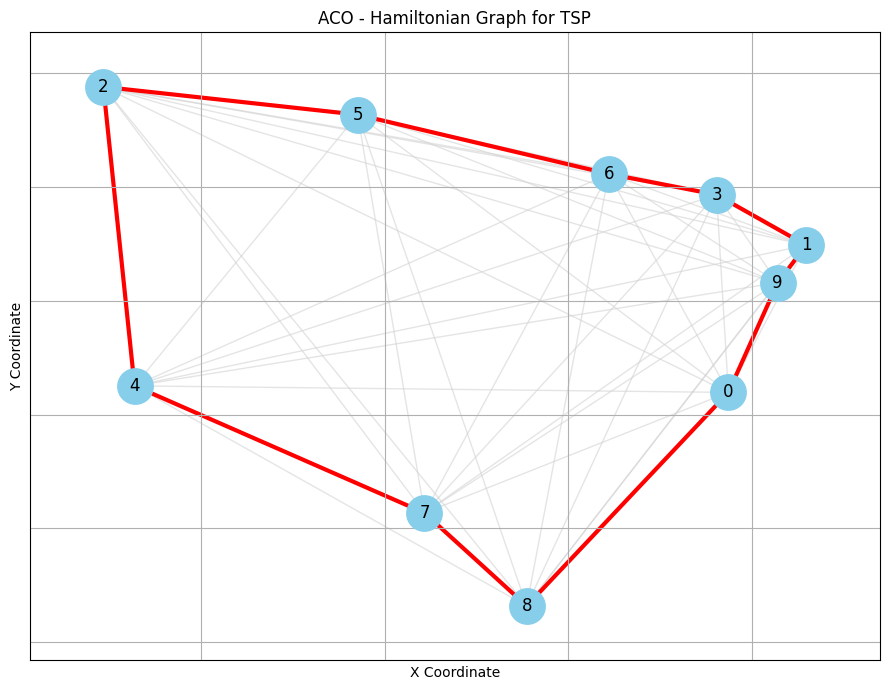

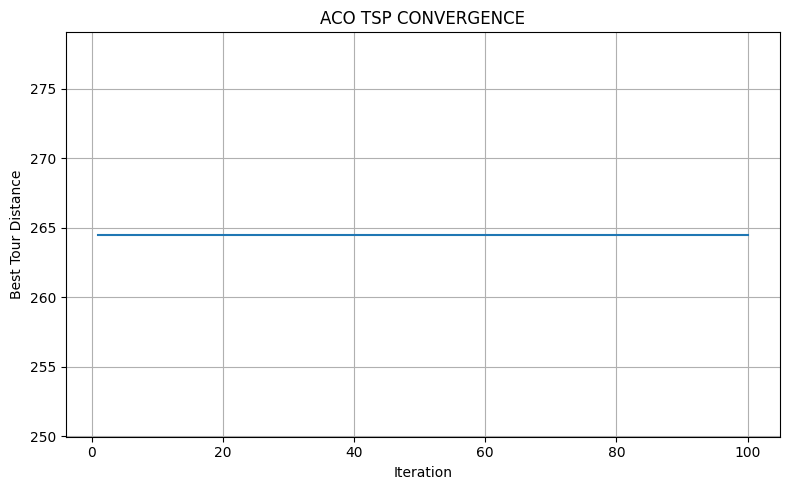


========== TSP RUNTIME ANALYSIS ==========

No. of Cities        Runtime (ms)        
5                    229.95              
10                   729.58              
15                   928.36              
20                   2133.44             
25                   2758.09             
30                   6487.73             


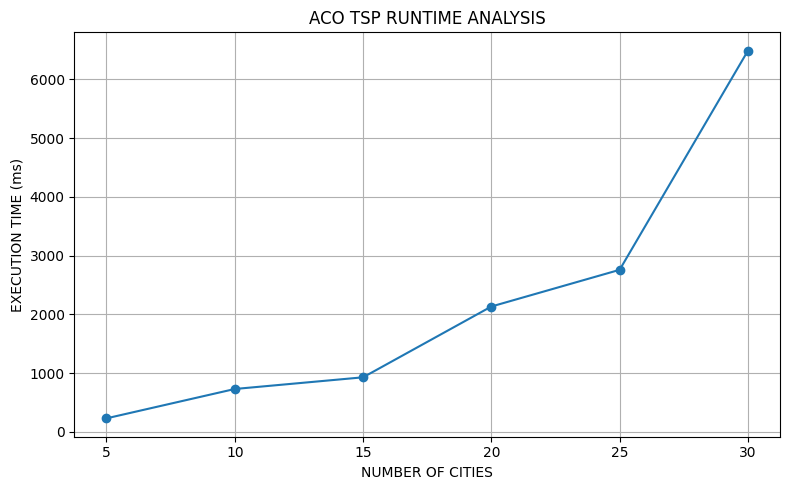

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time

# ---------------------------------------------------------
# STEP 1: GENERATE COMPLETE WEIGHTED GRAPH
# ---------------------------------------------------------

def generate_graph(n, seed=42):
    rng = np.random.default_rng(seed)

    coordinates = rng.uniform(0, 100, (n, 2))

    distance = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            distance[i][j] = np.linalg.norm(
                coordinates[i] - coordinates[j]
            )

    return coordinates, distance


# ---------------------------------------------------------
# STEP 2: CALCULATE TOUR DISTANCE
# ---------------------------------------------------------

def tour_distance(tour, distance):
    total = 0

    for i in range(len(tour)):
        total += distance[
            tour[i]
        ][tour[(i + 1) % len(tour)]]

    return total


# ---------------------------------------------------------
# STEP 3: 2-OPT LOCAL SEARCH
# ---------------------------------------------------------

def two_opt(tour, distance):
    best = tour[:]
    improved = True

    while improved:
        improved = False
        old_cost = tour_distance(best, distance)

        for i in range(1, len(best) - 1):
            for j in range(i + 1, len(best)):

                new_tour = (
                    best[:i] + best[i:j + 1][::-1]
                    + best[j + 1:]
                )

                new_cost = tour_distance(new_tour, distance)

                if new_cost < old_cost - 1e-9:
                    best = new_tour
                    improved = True
                    break

            if improved:
                break

    return best


# ---------------------------------------------------------
# STEP 4: ACO FOR TSP
# ---------------------------------------------------------

def aco_tsp(distance, ants=20, iterations=100,
            alpha=1, beta=2, rho=0.5, Q=100, seed=42):

    rng = np.random.default_rng(seed)
    n = len(distance)

    pheromone = np.ones((n, n))

    best_tour = None
    best_distance = float('inf')

    convergence = []

    for iteration in range(iterations):

        iteration_best = None
        iteration_cost = float('inf')

        for ant in range(ants):

            start = rng.integers(n)
            tour = [start]
            unvisited = set(range(n))
            unvisited.remove(start)

            while unvisited:

                current = tour[-1]
                allowed = list(unvisited)

                probabilities = []

                for city in allowed:
                    tau = pheromone[current][city]
                    eta = 1 / (distance[current][city] + 1e-10)

                    probabilities.append(
                        tau ** alpha * eta ** beta
                    )

                probabilities = np.array(probabilities)
                probabilities /= probabilities.sum()

                next_city = rng.choice(
                    allowed, p=probabilities
                )

                tour.append(next_city)
                unvisited.remove(next_city)

            # Apply local search
            tour = two_opt(tour, distance)

            cost = tour_distance(tour, distance)

            if cost < iteration_cost:
                iteration_cost = cost
                iteration_best = tour[:]

            if cost < best_distance:
                best_distance = cost
                best_tour = tour[:]

        # Pheromone evaporation
        pheromone *= (1 - rho)

        # Best ant deposits pheromone
        deposit = Q / (iteration_cost + 1e-10)

        for i in range(n):
            a = iteration_best[i]
            b = iteration_best[(i + 1) % n]

            pheromone[a][b] += deposit
            pheromone[b][a] += deposit

        convergence.append(best_distance)

    return best_tour, best_distance, convergence


# ---------------------------------------------------------
# STEP 5: DISPLAY HAMILTONIAN GRAPH
# ---------------------------------------------------------

def display_graph(coordinates, distance, tour):

    G = nx.Graph()
    n = len(coordinates)

    for i in range(n):
        G.add_node(i)

    # Complete graph: every pair of cities is connected
    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(
                i, j,
                weight=round(distance[i][j], 2)
            )

    pos = {
        i: coordinates[i]
        for i in range(n)
    }

    plt.figure(figsize=(9, 7))

    nx.draw_networkx_edges(
        G, pos, edge_color="lightgray",
        width=1, alpha=0.6
    )

    nx.draw_networkx_nodes(
        G, pos, node_color="skyblue",
        node_size=650
    )

    nx.draw_networkx_labels(G, pos)

    # Draw Hamiltonian cycle
    cycle_edges = [
        (tour[i], tour[(i + 1) % n])
        for i in range(n)
    ]

    nx.draw_networkx_edges(
        G, pos, edgelist=cycle_edges,
        edge_color="red", width=3
    )

    plt.title("ACO - Hamiltonian Graph for TSP")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 6: PERFORMANCE ANALYSIS
# ---------------------------------------------------------

def benchmark():

    sizes = [5, 10, 15, 20, 25, 30]
    times = []

    print("\n========== TSP RUNTIME ANALYSIS ==========")

    for n in sizes:

        coordinates, distance = generate_graph(
            n, seed=100 + n
        )

        start = time.perf_counter()

        aco_tsp(
            distance,
            ants=10,
            iterations=30,
            seed=200 + n
        )

        end = time.perf_counter()

        runtime = (end - start) * 1000
        times.append(runtime)

    print("\n{:<20} {:<20}".format(
        "No. of Cities", "Runtime (ms)"
    ))

    for n, t in zip(sizes, times):
        print("{:<20} {:<20.2f}".format(n, t))

    plt.figure(figsize=(8, 5))
    plt.plot(sizes, times, marker='o')

    plt.title("ACO TSP RUNTIME ANALYSIS")
    plt.xlabel("NUMBER OF CITIES")
    plt.ylabel("EXECUTION TIME (ms)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 7: MAIN FUNCTION
# ---------------------------------------------------------

def main():

    n = 10

    coordinates, distance = generate_graph(n)

    start = time.perf_counter()

    best_tour, best_distance, convergence = aco_tsp(
        distance,
        ants=20,
        iterations=100,
        alpha=1,
        beta=2,
        rho=0.5,
        Q=100
    )

    end = time.perf_counter()

    print("\n========== ACO TSP RESULT ==========")

    print("Number of Cities:", n)

    print(
        "Hamiltonian Cycle:",
        " -> ".join(map(str, best_tour + [best_tour[0]]))
    )

    print("Best Tour Distance:", round(best_distance, 2))

    print("Every city visited once:",
          len(set(best_tour)) == n)

    print("Execution Time:",
          round((end - start) * 1000, 2), "ms")

    print("====================================")

    display_graph(coordinates, distance, best_tour)

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(convergence) + 1), convergence)

    plt.title("ACO TSP CONVERGENCE")
    plt.xlabel("Iteration")
    plt.ylabel("Best Tour Distance")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    benchmark()


if __name__ == "__main__":
    main()

